# 07 - Model Training: Logistic Regression & Decision Tree

Train two classifiers to predict `team1_won` from the features built in `06_feature_engineering.ipynb`:

- **Logistic Regression**: a linear baseline whose coefficients are easy to read.
- **Decision Tree**: captures simple non-linear rules (e.g. "much better form AND batting first").

**Evaluation is time-based.** The models train on 2008-2023 and are tested on 2024-2026, so every test match comes after all the training data, just like a real prediction. (The random split in `05_preprocessing.ipynb` mixes future matches into training, which isn't realistic for a predictor.)

In [1]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import (accuracy_score, roc_auc_score, log_loss,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

MODELS_DIR = '../models'
IMAGES_DIR = '../images'

matches = pd.read_csv('../data/processed/matches_features.csv', parse_dates=['date'])
matches = matches.sort_values('date').reset_index(drop=True)
matches['year'] = matches['date'].dt.year
matches.shape

(1187, 27)

## 1. Model features

The label-encoded team/venue ids from notebook 05 are arbitrary numbers (team 7 isn't "more" than team 3), so they'd mislead logistic regression. Team strength is already captured by the engineered win-% features, so we use:

- `team1_bats_first`: derived from toss winner + toss decision (known before the first ball).
- `*_diff`: team1's stat minus team2's stat for overall win %, head-to-head, venue win %, and last-5 form. One signed number per stat keeps the model symmetric and small.

In [2]:
matches['toss_winner_is_team1'] = (matches['toss_winner'] == matches['team1']).astype(int)
matches['team1_bats_first'] = (
    matches['toss_winner_is_team1'] == (matches['toss_decision'] == 'bat')
).astype(int)

stat_cols = ['team_win_pct', 'h2h_win_rate', 'venue_win_pct', 'recent_form_5']
for s in stat_cols:
    matches[f'{s}_diff'] = matches[f'team1_{s}'] - matches[f'team2_{s}']

FEATURES = ['team1_bats_first'] + [f'{s}_diff' for s in stat_cols]
TARGET = 'team1_won'
matches[FEATURES + [TARGET]].describe().T

,count,mean,std,min,25%,50%,75%,max
team1_bats_first,1187.0,0.752317,0.431849,0.0,1.000000,1.000000,1.000000,1.0
team_win_pct_diff,1187.0,-0.003668,0.149223,-1.0,-0.078102,-0.000852,0.074871,1.0
h2h_win_rate_diff,1187.0,-0.009273,0.422279,-1.0,-0.200000,0.000000,0.176471,1.0
venue_win_pct_diff,1187.0,0.003830,0.386853,-1.0,-0.250000,0.000000,0.262174,1.0
recent_form_5_diff,1187.0,0.001404,0.331363,-1.0,-0.200000,0.000000,0.200000,1.0
team1_won,1187.0,0.502106,0.500206,0.0,0.000000,1.000000,1.000000,1.0


## 2. Time-based train/test split

In [3]:
TEST_FROM_YEAR = 2024

train = matches[matches['year'] < TEST_FROM_YEAR]
test = matches[matches['year'] >= TEST_FROM_YEAR]
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

print(f'train: {len(train)} matches ({train.year.min()}-{train.year.max()})')
print(f'test:  {len(test)} matches ({test.year.min()}-{test.year.max()})')
print('team1 win rate - train: %.3f, test: %.3f' % (y_train.mean(), y_test.mean()))

train: 1005 matches (2008-2023)
test:  182 matches (2024-2026)
team1 win rate - train: 0.510, test: 0.456


## 3. Baselines

Any model has to beat these to be worth using:
- **Always team1**: predict team1 wins every match.
- **Better record**: pick whichever team has the higher all-time win % going into the match.

In [4]:
baselines = {
    'Always team1': np.ones(len(test), dtype=int),
    'Better record': (test['team_win_pct_diff'] > 0).astype(int).values,
}
for name, pred in baselines.items():
    print(f'{name:15s} accuracy: {accuracy_score(y_test, pred):.3f}')

Always team1    accuracy: 0.456
Better record   accuracy: 0.462


## 4. Hyperparameter tuning

`TimeSeriesSplit` cross-validation on the training years only: each fold trains on earlier matches and validates on the next block, so tuning never sees the future either. ROC AUC is the selection metric.

In [5]:
cv = TimeSeriesSplit(n_splits=5)

log_reg_search = GridSearchCV(
    make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    {'logisticregression__C': [0.001, 0.01, 0.1, 1, 10]},
    cv=cv, scoring='roc_auc',
).fit(X_train, y_train)

tree_search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    {'max_depth': [2, 3, 4, 5, 6], 'min_samples_leaf': [10, 20, 40, 80]},
    cv=cv, scoring='roc_auc',
).fit(X_train, y_train)

print('Logistic Regression:', log_reg_search.best_params_, 'CV AUC %.3f' % log_reg_search.best_score_)
print('Decision Tree:      ', tree_search.best_params_, 'CV AUC %.3f' % tree_search.best_score_)

Logistic Regression: {'logisticregression__C': 0.01} CV AUC 0.559
Decision Tree:       {'max_depth': 3, 'min_samples_leaf': 40} CV AUC 0.538


## 5. Test-set evaluation (2024-2026)

In [6]:
models = {
    'Logistic Regression': log_reg_search.best_estimator_,
    'Decision Tree': tree_search.best_estimator_,
}

rows = []
for name, model in models.items():
    proba = model.predict_proba(X_test)[:, 1]
    rows.append({
        'model': name,
        'accuracy': accuracy_score(y_test, proba >= 0.5),
        'roc_auc': roc_auc_score(y_test, proba),
        'log_loss': log_loss(y_test, proba),
    })
results = pd.DataFrame(rows).set_index('model').round(3)
results

,accuracy,roc_auc,log_loss
model,,,
Logistic Regression,0.462,0.420,0.697
Decision Tree,0.423,0.437,0.728


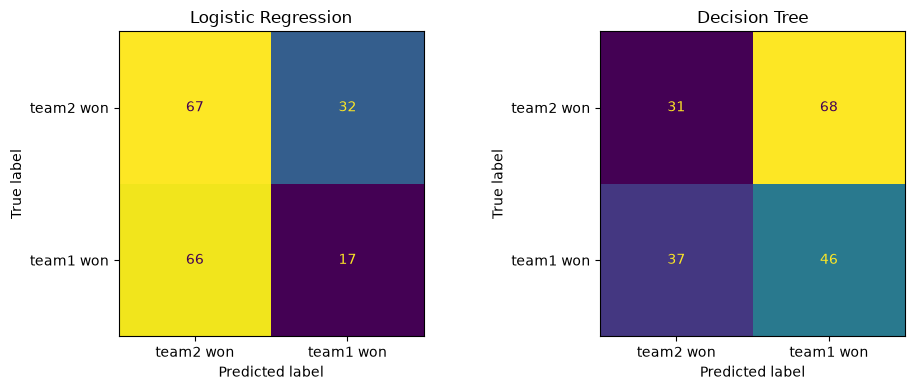

Logistic Regression
              precision    recall  f1-score   support

   team2 won       0.50      0.68      0.58        99
   team1 won       0.35      0.20      0.26        83

    accuracy                           0.46       182
   macro avg       0.43      0.44      0.42       182
weighted avg       0.43      0.46      0.43       182

Decision Tree
              precision    recall  f1-score   support

   team2 won       0.46      0.31      0.37        99
   team1 won       0.40      0.55      0.47        83

    accuracy                           0.42       182
   macro avg       0.43      0.43      0.42       182
weighted avg       0.43      0.42      0.41       182



In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, model.predict(X_test)),
                           display_labels=['team2 won', 'team1 won']).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.savefig(f'{IMAGES_DIR}/model_confusion_matrices.png', dpi=120)
plt.show()

for name, model in models.items():
    print(name)
    print(classification_report(y_test, model.predict(X_test), target_names=['team2 won', 'team1 won']))

## 6. What the models learned

Logistic regression coefficients are on standardized features, so their sizes are comparable: positive means the feature pushes toward a team1 win.

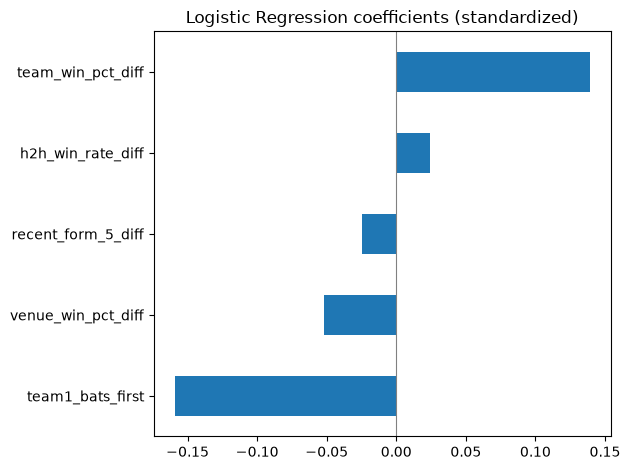

team1_bats_first     -0.159372
venue_win_pct_diff   -0.052281
recent_form_5_diff   -0.024453
h2h_win_rate_diff     0.024250
team_win_pct_diff     0.139292
dtype: float64

In [8]:
coefs = pd.Series(
    models['Logistic Regression'][-1].coef_[0], index=FEATURES
).sort_values()
coefs.plot.barh(title='Logistic Regression coefficients (standardized)')
plt.axvline(0, color='grey', lw=0.8)
plt.tight_layout()
plt.savefig(f'{IMAGES_DIR}/logreg_coefficients.png', dpi=120)
plt.show()
coefs

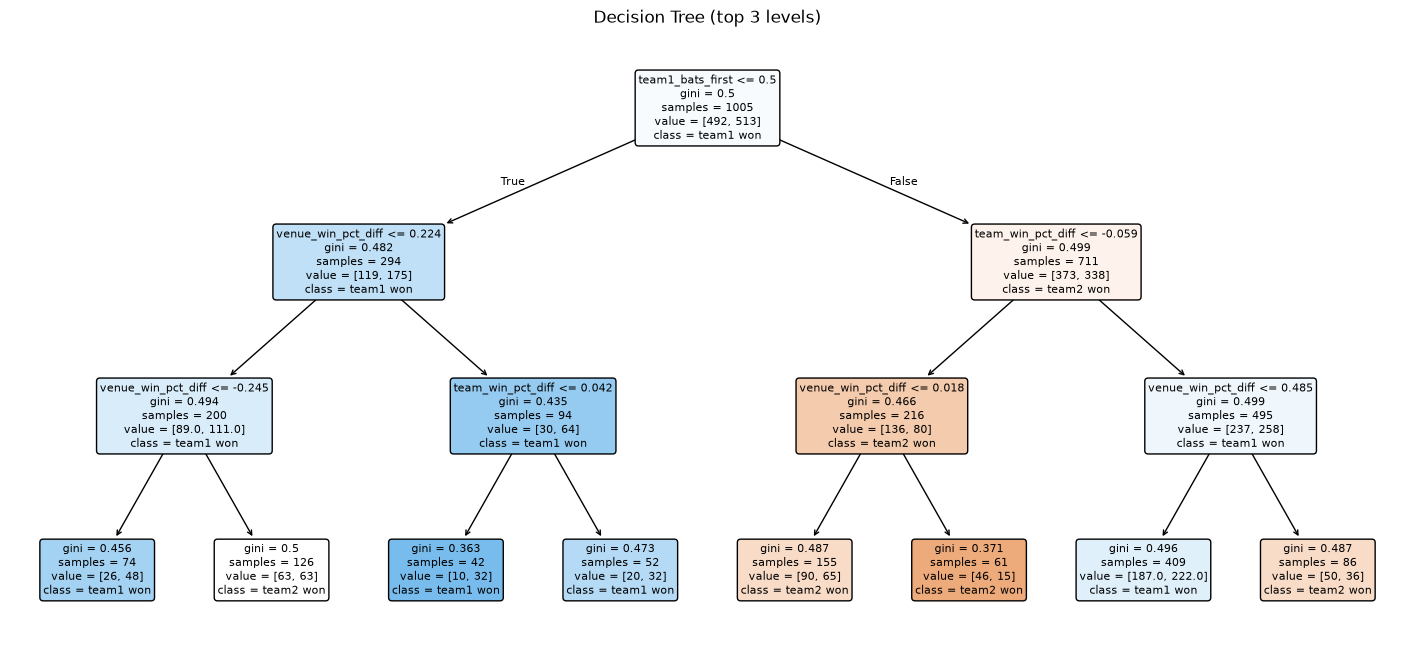

venue_win_pct_diff    0.392096
team_win_pct_diff     0.344991
team1_bats_first      0.262913
h2h_win_rate_diff     0.000000
recent_form_5_diff    0.000000
dtype: float64

In [9]:
tree = models['Decision Tree']
plt.figure(figsize=(18, 8))
plot_tree(tree, feature_names=FEATURES, class_names=['team2 won', 'team1 won'],
          filled=True, rounded=True, fontsize=8, max_depth=3)
plt.title('Decision Tree (top 3 levels)')
plt.savefig(f'{IMAGES_DIR}/decision_tree.png', dpi=120, bbox_inches='tight')
plt.show()

pd.Series(tree.feature_importances_, index=FEATURES).sort_values(ascending=False)

## 7. Season-by-season (walk-forward) accuracy

A single test window can be lucky or unlucky. Here, for each season from 2016, both models are retrained on all *earlier* seasons with the tuned hyperparameters and scored on that season.

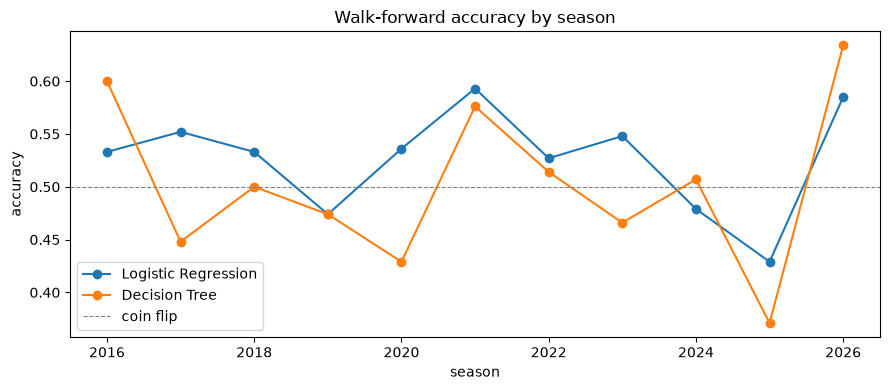

mean accuracy: {'Logistic Regression': 0.526, 'Decision Tree': 0.502}


,matches,Logistic Regression,Decision Tree
season,,,
2016,60,0.533,0.600
2017,58,0.552,0.448
2018,60,0.533,0.500
2019,57,0.474,0.474
2020,56,0.536,0.429
2021,59,0.593,0.576
2022,74,0.527,0.514
2023,73,0.548,0.466
2024,71,0.479,0.507


In [10]:
walk = []
for year in range(2016, matches['year'].max() + 1):
    past, season = matches[matches['year'] < year], matches[matches['year'] == year]
    row = {'season': year, 'matches': len(season)}
    for name, model in models.items():
        fitted = clone(model).fit(past[FEATURES], past[TARGET])
        row[name] = accuracy_score(season[TARGET], fitted.predict(season[FEATURES]))
    walk.append(row)
walk = pd.DataFrame(walk).set_index('season').round(3)

walk[list(models)].plot(marker='o', figsize=(9, 4), title='Walk-forward accuracy by season')
plt.axhline(0.5, color='grey', ls='--', lw=0.8, label='coin flip')
plt.ylabel('accuracy')
plt.legend()
plt.tight_layout()
plt.savefig(f'{IMAGES_DIR}/walk_forward_accuracy.png', dpi=120)
plt.show()

print('mean accuracy:', walk[list(models)].mean().round(3).to_dict())
walk

## 8. Train final models on all seasons and save

The held-out numbers above are the honest estimate of performance. For actual use, both models are refit on every match (2008-2026) with the tuned hyperparameters, so they include the most recent form.

In [11]:
X_all, y_all = matches[FEATURES], matches[TARGET]
final_models = {name: clone(model).fit(X_all, y_all) for name, model in models.items()}

joblib.dump(final_models['Logistic Regression'], f'{MODELS_DIR}/logistic_regression.joblib')
joblib.dump(final_models['Decision Tree'], f'{MODELS_DIR}/decision_tree.joblib')

metadata = {
    'features': FEATURES,
    'target': TARGET,
    'trained_on': f"{matches['year'].min()}-{matches['year'].max()} ({len(matches)} matches)",
    'evaluation': f'trained < {TEST_FROM_YEAR}, tested {TEST_FROM_YEAR}-{matches.year.max()} ({len(test)} matches)',
    'hyperparameters': {
        'Logistic Regression': log_reg_search.best_params_,
        'Decision Tree': tree_search.best_params_,
    },
    'test_metrics': results.to_dict(orient='index'),
    'walk_forward_mean_accuracy': walk[list(models)].mean().round(3).to_dict(),
}
with open(f'{MODELS_DIR}/model_metadata.json', 'w') as f:
    json.dump(metadata, f, indent=2)

print(json.dumps(metadata, indent=2))

{
  "features": [
    "team1_bats_first",
    "team_win_pct_diff",
    "h2h_win_rate_diff",
    "venue_win_pct_diff",
    "recent_form_5_diff"
  ],
  "target": "team1_won",
  "trained_on": "2008-2026 (1187 matches)",
  "evaluation": "trained < 2024, tested 2024-2026 (182 matches)",
  "hyperparameters": {
    "Logistic Regression": {
      "logisticregression__C": 0.01
    },
    "Decision Tree": {
      "max_depth": 3,
      "min_samples_leaf": 40
    }
  },
  "test_metrics": {
    "Logistic Regression": {
      "accuracy": 0.462,
      "roc_auc": 0.42,
      "log_loss": 0.697
    },
    "Decision Tree": {
      "accuracy": 0.423,
      "roc_auc": 0.437,
      "log_loss": 0.728
    }
  },
  "walk_forward_mean_accuracy": {
    "Logistic Regression": 0.526,
    "Decision Tree": 0.502
  }
}


## 9. Example prediction

Predict a match from the latest stats of two teams. `team_snapshot` pulls each team's most recent pre-match stats from the feature table.

In [12]:
def team_snapshot(team, opponent, venue):
    """Latest overall win %, form, h2h vs opponent, and venue win % for `team`."""
    def latest(rows, stat):
        if rows.empty:
            return 0.5
        r = rows.iloc[-1]
        side = 'team1' if r['team1'] == team else 'team2'
        return r[f'{side}_{stat}']

    played = matches[(matches['team1'] == team) | (matches['team2'] == team)]
    vs = played[(played['team1'] == opponent) | (played['team2'] == opponent)]
    at_venue = played[played['venue'] == venue]
    return {
        'team_win_pct': latest(played, 'team_win_pct'),
        'recent_form_5': latest(played, 'recent_form_5'),
        'h2h_win_rate': latest(vs, 'h2h_win_rate'),
        'venue_win_pct': latest(at_venue, 'venue_win_pct'),
    }


def predict_match(team1, team2, venue, team1_bats_first, model_name='Logistic Regression'):
    s1, s2 = team_snapshot(team1, team2, venue), team_snapshot(team2, team1, venue)
    row = {'team1_bats_first': int(team1_bats_first)}
    row.update({f'{k}_diff': s1[k] - s2[k] for k in stat_cols})
    p = final_models[model_name].predict_proba(pd.DataFrame([row])[FEATURES])[0, 1]
    return {team1: round(p, 3), team2: round(1 - p, 3)}


predict_match('Mumbai Indians', 'Chennai Super Kings', 'Wankhede Stadium', team1_bats_first=True)

{'Mumbai Indians': np.float64(0.471), 'Chennai Super Kings': np.float64(0.529)}

## Summary

- Both models are compared against the baselines and coin-flip (50%) above. Pre-match IPL results are close to a coin flip with team-history features alone: squads change every auction, and T20 outcomes are high-variance.
- Saved artifacts: `models/logistic_regression.joblib`, `models/decision_tree.joblib`, `models/model_metadata.json`.
- Ideas likely to add real signal: squad/player-strength features (auction changes make team history stale), and in-match features (score, wickets, overs) for a live win-probability model, which is far more predictable than pre-match.